## Experiment 5 (YOLO11n, 960 imgsz w/ 3758 images)

In [2]:
# ============================================================
# EXPERIMENT 5 — FULL DATASET TRAINING
# ============================================================

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import matplotlib.pyplot as plt

# Project directories
PROJECT_DIR = Path(r"D:\Projects\Wildfire_Smoke_Project")

DATASET_DIR = PROJECT_DIR / "datasets" / "experiment_5"
DATA_YAML = DATASET_DIR / "data.yaml"

EXPERIMENTS_DIR = PROJECT_DIR / "experiments"
EVALUATION_DIR = PROJECT_DIR / "evaluations"

# Confirm the dataset configuration exists
print("Dataset configuration exists:", DATA_YAML.exists())
print("Dataset path:", DATASET_DIR)

Dataset configuration exists: True
Dataset path: D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5


In [3]:
# ============================================================
# SECTION 2 — DATASET VERIFICATION
# ============================================================

# Read the manifest generated by prepare_experiment_5.py
manifest = pd.read_csv(DATASET_DIR / "split_manifest.csv")

# Count images and recording groups in each split
summary = manifest.groupby("split").agg(
    images=("filename", "count"),
    recordings=("recording_id", "nunique"),
    smoke_positive=("smoke_positive", "sum"),
)

# Calculate smoke-negative images
summary["smoke_negative"] = (
    summary["images"] - summary["smoke_positive"]
)

# Check whether any recording appears in both splits
train_recordings = set(
    manifest.loc[manifest["split"] == "train", "recording_id"]
)

val_recordings = set(
    manifest.loc[manifest["split"] == "val", "recording_id"]
)

overlapping_recordings = train_recordings & val_recordings

# Display dataset summary
print("EXPERIMENT 5 — DATASET SUMMARY")
print("-" * 45)

display(summary)

print(f"\nTotal images: {len(manifest)}")
print(f"Overlapping recordings: {len(overlapping_recordings)}")

# Stop if recording-level leakage is detected
assert len(overlapping_recordings) == 0, (
    "Recording leakage detected between train and validation!"
)

assert len(manifest) == 3758, "Unexpected dataset size!"

print("\nDataset verification passed!")

EXPERIMENT 5 — DATASET SUMMARY
---------------------------------------------


,images,recordings,smoke_positive,smoke_negative
split,,,,
train,3006,86,2026,980
val,752,17,439,313



Total images: 3758
Overlapping recordings: 0

Dataset verification passed!


In [4]:
# ============================================================
# SECTION 3 — EXPERIMENT 5 TRAINING
# ============================================================

# Initialize a new YOLO11n model with pretrained weights
model_exp5 = YOLO("yolo11n.pt")

# Train using the expanded, recording-separated dataset
results_exp5 = model_exp5.train(
    data=str(DATA_YAML),

    # Training configuration
    epochs=50,
    imgsz=960,
    batch=4,
    device=0,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Memory management (GTX 1660 SUPER)
    workers=0,
    cache=False,

    # Save results separately from previous experiments
    project=str(EXPERIMENTS_DIR),
    name="experiment_5_full_dataset",
    exist_ok=False,

    # Save checkpoints and training plots
    save=True,
    plots=True,
)

print("\nExperiment 5 training complete!")

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_de

In [6]:
# Find all Experiment 5 checkpoints
checkpoints = sorted(
    EXPERIMENTS_DIR.glob("experiment_5*/weights/*.pt")
)

print(f"Found {len(checkpoints)} checkpoints:\n")

for checkpoint in checkpoints:
    print(checkpoint.relative_to(EXPERIMENTS_DIR))

Found 2 checkpoints:

experiment_5_full_dataset-2\weights\best.pt
experiment_5_full_dataset-2\weights\last.pt


In [7]:
# ============================================================
# SECTION 4 — EXPERIMENT 5 EVALUATION
# ============================================================

# Load the best checkpoint saved during training
checkpoint = (
    EXPERIMENTS_DIR /
    "experiment_5_full_dataset-2" /
    "weights" / "best.pt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

model_exp5 = YOLO(str(checkpoint))

# Evaluate using Experiment 5's validation dataset
metrics_exp5 = model_exp5.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=960,
    batch=4,
    device=0,
    plots=True,
    project=str(EVALUATION_DIR),
    name="experiment_5_evaluation",
    exist_ok=True,
)

# Extract evaluation metrics
p = metrics_exp5.box.mp
r = metrics_exp5.box.mr

results = pd.DataFrame([{
    "Model": "Experiment 5 — Full Dataset",
    "Precision": p,
    "Recall": r,
    "F1": 2 * p * r / (p + r) if p + r else 0,
    "mAP50": metrics_exp5.box.map50,
    "mAP50:95": metrics_exp5.box.map,
}])

print("\nEXPERIMENT 5 — EVALUATION RESULTS")
display(results.round(4))

Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1852.5±489.0 MB/s, size: 727.9 KB)
val: Scanning D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\labels\val.cache... 752 images, 313 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 752/752  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 188/188 4.8it/s 39.3s<0.2s
                   all        752        439      0.654      0.516      0.579      0.294
Speed: 2.2ms preprocess, 6.9ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to D:\Projects\Wildfire_Smoke_Project\evaluations\experiment_5_evaluation

EXPERIMENT 5 — EVALUATION RESULTS


,Model,Precision,Recall,F1,mAP50,mAP50:95
0,Experiment 5 — Full Dataset,0.6539,0.5164,0.5771,0.5793,0.2937


## Experiment 6 (YOLO11s, 960 imgsz w/ 3758 images)

In [3]:
# ============================================================
# SECTION 5 — EXPERIMENT 6: YOLO11s
# ============================================================

from ultralytics import YOLO

# Initialize the larger pretrained YOLO11s model
model_exp6 = YOLO("yolo11s.pt")

# Train on the same dataset used by Experiment 5
results_exp6 = model_exp6.train(
    data=str(DATA_YAML),

    # Training configuration
    epochs=50,
    imgsz=960,
    batch=2,  # Smaller batch to reduce GPU memory usage
    device=0,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Memory management
    workers=0,
    cache=False,
    amp=False,  # Avoid the AMP compatibility warning

    # Save checkpoints periodically
    save=True,
    save_period=5,
    plots=True,

    # Keep Experiment 6 separate
    project=str(EXPERIMENTS_DIR),
    name="experiment_6_yolo11s_full_dataset",
    exist_ok=False,
)

print("\nExperiment 6 training complete!")

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_d

In [6]:
# ============================================================
# SECTION 6 — EXPERIMENT 6 EVALUATION
# ============================================================

# Load the best checkpoint saved during training
checkpoint = (
    EXPERIMENTS_DIR /
    "experiment_6_yolo11s_full_dataset" /
    "weights" / "best.pt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

model_exp6 = YOLO(str(checkpoint))

# Evaluate using Experiment 6's validation dataset
# (Same 752 images used in Experiment 5)
metrics_exp6 = model_exp6.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=960,
    batch=2,
    device=0,
    plots=True,
    project=str(EVALUATION_DIR),
    name="experiment_6_evaluation",
    exist_ok=True,
)

# Extract evaluation metrics
p = metrics_exp6.box.mp
r = metrics_exp6.box.mr

results_exp6 = pd.DataFrame([{
    "Model": "Experiment 6 — YOLO11s",
    "Precision": p,
    "Recall": r,
    "F1": 2 * p * r / (p + r) if p + r else 0,
    "mAP50": metrics_exp6.box.map50,
    "mAP50:95": metrics_exp6.box.map,
}])

print("\nEXPERIMENT 6 — EVALUATION RESULTS")
display(results_exp6.round(4))

Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 81.2±21.4 MB/s, size: 655.4 KB)
val: Scanning D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\labels\val.cache... 752 images, 313 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 752/752  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 376/376 8.1it/s 46.5s<0.0ss
                   all        752        439      0.656      0.538      0.584      0.309
Speed: 1.9ms preprocess, 16.8ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to D:\Projects\Wildfire_Smoke_Project\evaluations\experiment_6_evaluation

EXPERIMENT 6 — EVALUATION RESULTS


,Model,Precision,Recall,F1,mAP50,mAP50:95
0,Experiment 6 — YOLO11s,0.6565,0.5376,0.5911,0.5838,0.3091


In [3]:
# ============================================================
# SECTION 7 — EXPERIMENT 6 CONFIDENCE THRESHOLD EVALUATION
# ============================================================

# Load the best Experiment 6 checkpoint
checkpoint = (
    EXPERIMENTS_DIR /
    "experiment_6_yolo11s_full_dataset" /
    "weights" / "best.pt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

model_exp6 = YOLO(str(checkpoint))

# Evaluate with a minimum confidence threshold of 25%
metrics_exp6_conf025 = model_exp6.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=960,
    batch=2,
    device=0,
    conf=0.25,
    plots=True,
    project=str(EVALUATION_DIR),
    name="experiment_6_evaluation_conf025",
    exist_ok=True,
)

print("\nConfidence threshold evaluation complete!")

Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 89.0±9.4 MB/s, size: 645.7 KB)
val: Scanning D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\labels\val.cache... 752 images, 313 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 752/752  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 376/376 8.1it/s 46.5s<0.1ss
                   all        752        439      0.623       0.56      0.501      0.271
Speed: 2.3ms preprocess, 17.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to D:\Projects\Wildfire_Smoke_Project\evaluations\experiment_6_evaluation_conf025

Confidence threshold evaluation complete!


In [4]:
# ============================================================
# SECTION 8 — EXPERIMENT 6 CONFIDENCE THRESHOLD ANALYSIS
# ============================================================

# Load the best Experiment 6 checkpoint
checkpoint = (
    EXPERIMENTS_DIR /
    "experiment_6_yolo11s_full_dataset" /
    "weights" / "best.pt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

model_exp6 = YOLO(str(checkpoint))

# Confidence thresholds to evaluate
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

# Evaluate the model at each confidence threshold
for conf in thresholds:

    print(f"\nEvaluating confidence threshold: {conf:.2f}")

    metrics = model_exp6.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=960,
        batch=2,
        device=0,
        conf=conf,
        plots=True,
        project=str(EVALUATION_DIR),
        name=f"experiment_6_conf_{conf:.2f}",
        exist_ok=True,
    )

    # Extract counts from the confusion matrix
    # Rows represent predictions; columns represent ground truth
    matrix = metrics.confusion_matrix.matrix

    tp = int(matrix[0, 0])
    fp = int(matrix[0, 1])
    fn = int(matrix[1, 0])

    # Calculate metrics at this specific confidence threshold
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    # Store results for comparison
    threshold_results.append({
        "Confidence": conf,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    })

# Create and display the comparison table
threshold_df = pd.DataFrame(threshold_results)

print("\nEXPERIMENT 6 — CONFIDENCE THRESHOLD COMPARISON")
display(threshold_df.round(4))

# Save the results for the final report
threshold_df.to_csv(
    EVALUATION_DIR / "experiment_6_threshold_comparison.csv",
    index=False,
)

# Identify the threshold with the highest F1 score
best_row = threshold_df.loc[threshold_df["F1"].idxmax()]

print(f"\nBest confidence threshold by F1: {best_row['Confidence']:.2f}")
print(f"Best F1 score: {best_row['F1']:.4f}")


Evaluating confidence threshold: 0.10
Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1757.0±302.3 MB/s, size: 659.8 KB)
val: Scanning D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\labels\val.cache... 752 images, 313 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 752/752  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 376/376 8.0it/s 47.0s<0.1ss
                   all        752        439      0.656      0.538       0.54       0.29
Speed: 1.9ms preprocess, 17.3ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to D:\Projects\Wildfire_Smoke_Project\evaluations\experiment_6_conf_0.10

Evaluating confidence threshold: 0.15
Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER,

,Confidence,True Positives,False Positives,False Negatives,Precision,Recall,F1
0,0.10,278,328,161,0.4587,0.6333,0.5321
1,0.15,271,244,168,0.5262,0.6173,0.5681
2,0.20,263,196,176,0.5730,0.5991,0.5857
3,0.25,246,149,193,0.6228,0.5604,0.5899
4,0.30,228,110,211,0.6746,0.5194,0.5869
5,0.40,195,64,244,0.7529,0.4442,0.5587
6,0.50,154,28,285,0.8462,0.3508,0.4960



Best confidence threshold by F1: 0.25
Best F1 score: 0.5899


In [5]:
# ============================================================
# SECTION 10 — MEMORY-EFFICIENT FALSE-POSITIVE ANALYSIS
# ============================================================

import gc
import torch

# Release unused memory
gc.collect()
torch.cuda.empty_cache()

# Load the Experiment 6 model
checkpoint = (
    EXPERIMENTS_DIR /
    "experiment_6_yolo11s_full_dataset" /
    "weights" / "best.pt"
)

model_exp6 = YOLO(str(checkpoint))

# Load the dataset manifest
manifest = pd.read_csv(DATASET_DIR / "split_manifest.csv")

# Identify smoke-negative validation images
negative_images = manifest[
    (manifest["split"] == "val") &
    (manifest["smoke_positive"] == False)
]["filename"].tolist()

print(f"Evaluating {len(negative_images)} smoke-negative images")

# Create output directory
FP_DIR = EVALUATION_DIR / "experiment_6_false_positives"
FP_DIR.mkdir(parents=True, exist_ok=True)

false_positives = []

# Process one image at a time to minimize memory usage
for i, filename in enumerate(negative_images, start=1):

    image_path = DATASET_DIR / "images" / "val" / filename

    # Run inference on a single image
    result = model_exp6.predict(
        source=str(image_path),
        imgsz=960,
        conf=0.25,
        batch=1,
        device=0,
        verbose=False,
    )[0]

    # Record and save false-positive detections
    if len(result.boxes) > 0:

        result.save(filename=str(FP_DIR / filename))

        false_positives.append({
            "Image": filename,
            "False Positives": len(result.boxes),
            "Max Confidence": float(result.boxes.conf.max().item()),
        })

    # Release the current image's results
    del result

    # Periodically clean up unused memory
    if i % 25 == 0:
        gc.collect()
        torch.cuda.empty_cache()

        print(f"Processed {i}/{len(negative_images)} images")

# Create results table
fp_df = pd.DataFrame(
    false_positives,
    columns=["Image", "False Positives", "Max Confidence"]
).sort_values("Max Confidence", ascending=False)

# Display summary
print("\nFALSE-POSITIVE ANALYSIS")
print("-" * 45)
print(f"Negative images evaluated: {len(negative_images)}")
print(f"Images with false positives: {len(fp_df)}")
print(f"Total false-positive boxes: {fp_df['False Positives'].sum()}")
print(f"Image-level false-positive rate: {len(fp_df) / len(negative_images):.2%}")

display(fp_df.head(20).round(4))

# Save results
fp_df.to_csv(FP_DIR / "false_positives.csv", index=False)

Evaluating 313 smoke-negative images
Processed 25/313 images
Processed 50/313 images
Processed 75/313 images
Processed 100/313 images
Processed 125/313 images
Processed 150/313 images
Processed 175/313 images
Processed 200/313 images
Processed 225/313 images
Processed 250/313 images
Processed 275/313 images
Processed 300/313 images

FALSE-POSITIVE ANALYSIS
---------------------------------------------
Negative images evaluated: 313
Images with false positives: 4
Total false-positive boxes: 4
Image-level false-positive rate: 1.28%


,Image,False Positives,Max Confidence
3,1479065749_+01380.jpg,1,0.5326
0,1466357707_-01860.jpg,1,0.4263
2,1479065089_+00720.jpg,1,0.3194
1,1479064669_+00300.jpg,1,0.2578


In [6]:
# ============================================================
# SECTION 11 — SMOKE-POSITIVE ERROR ANALYSIS
# ============================================================

import gc
import torch
import numpy as np
from ultralytics.utils.metrics import box_iou

# Release unused memory
gc.collect()
torch.cuda.empty_cache()

# Load the dataset manifest
manifest = pd.read_csv(DATASET_DIR / "split_manifest.csv")

# Identify smoke-positive validation images
positive_images = manifest[
    (manifest["split"] == "val") &
    (manifest["smoke_positive"] == True)
]["filename"].tolist()

# Analysis thresholds
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

# Create output directory
ERROR_DIR = EVALUATION_DIR / "experiment_6_positive_errors"
ERROR_DIR.mkdir(parents=True, exist_ok=True)

error_results = []

print(f"Evaluating {len(positive_images)} smoke-positive images")

# Process one image at a time
for i, filename in enumerate(positive_images, start=1):

    image_path = DATASET_DIR / "images" / "val" / filename
    label_path = DATASET_DIR / "labels" / "val" / (
        Path(filename).stem + ".txt"
    )

    # Generate predictions
    result = model_exp6.predict(
        source=str(image_path),
        imgsz=960,
        conf=CONF_THRESHOLD,
        batch=1,
        device=0,
        verbose=False,
    )[0]

    height, width = result.orig_shape

    # Convert YOLO annotations into pixel-based xyxy boxes
    ground_truth = []

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        _, x, y, w, h = map(float, line.split())

        ground_truth.append([
            (x - w / 2) * width,
            (y - h / 2) * height,
            (x + w / 2) * width,
            (y + h / 2) * height,
        ])

    gt_boxes = torch.tensor(
        ground_truth, dtype=torch.float32
    ).reshape(-1, 4)

    pred_boxes = result.boxes.xyxy.cpu()
    confidences = result.boxes.conf.cpu()

    # Calculate IoU between every prediction and annotation
    ious = box_iou(pred_boxes, gt_boxes).numpy()

    matched_gt = set()

    correct = 0
    poor_localization = 0
    duplicates = 0
    background = 0

    # Process highest-confidence predictions first
    prediction_order = torch.argsort(
        confidences, descending=True
    ).tolist()

    for pred_idx in prediction_order:

        overlaps = ious[pred_idx]

        # Find unmatched annotations with sufficient overlap
        candidates = [
            j for j in range(len(gt_boxes))
            if overlaps[j] >= IOU_THRESHOLD
            and j not in matched_gt
        ]

        if candidates:
            best_gt = max(candidates, key=lambda j: overlaps[j])
            matched_gt.add(best_gt)
            correct += 1

        elif overlaps.max() >= IOU_THRESHOLD:
            duplicates += 1

        elif overlaps.max() > 0:
            poor_localization += 1

        else:
            background += 1

    # Count unmatched ground-truth annotations
    false_negatives = len(gt_boxes) - len(matched_gt)

    # Count smoke objects with no overlapping prediction
    completely_missed = sum(
        not np.any(ious[:, j] > 0)
        for j in range(len(gt_boxes))
    )

    # Save images containing detection errors
    if poor_localization or duplicates or background or false_negatives:
        result.save(filename=str(ERROR_DIR / filename))

    # Record image-level results
    error_results.append({
        "Image": filename,
        "Ground Truth": len(gt_boxes),
        "Predictions": len(pred_boxes),
        "Correct Detections": correct,
        "Poor Localization": poor_localization,
        "Duplicate Detections": duplicates,
        "Background Detections": background,
        "False Negatives": false_negatives,
        "Completely Missed": completely_missed,
    })

    del result

    # Periodically release unused memory
    if i % 25 == 0:
        gc.collect()
        torch.cuda.empty_cache()

        print(f"Processed {i}/{len(positive_images)} images")

# Create results table
error_df = pd.DataFrame(error_results)

# Display overall error counts
print("\nSMOKE-POSITIVE ERROR ANALYSIS")
print("-" * 45)

display(
    error_df.drop(columns=["Image"])
    .sum()
    .to_frame("Count")
)

# Save detailed results
error_df.to_csv(
    ERROR_DIR / "positive_error_analysis.csv",
    index=False,
)

Evaluating 439 smoke-positive images
Processed 25/439 images
Processed 50/439 images
Processed 75/439 images
Processed 100/439 images
Processed 125/439 images
Processed 150/439 images
Processed 175/439 images
Processed 200/439 images
Processed 225/439 images
Processed 250/439 images
Processed 275/439 images
Processed 300/439 images
Processed 325/439 images
Processed 350/439 images
Processed 375/439 images
Processed 400/439 images
Processed 425/439 images

SMOKE-POSITIVE ERROR ANALYSIS
---------------------------------------------


,Count
Ground Truth,439
Predictions,345
Correct Detections,242
Poor Localization,83
Duplicate Detections,5
Background Detections,15
False Negatives,197
Completely Missed,138


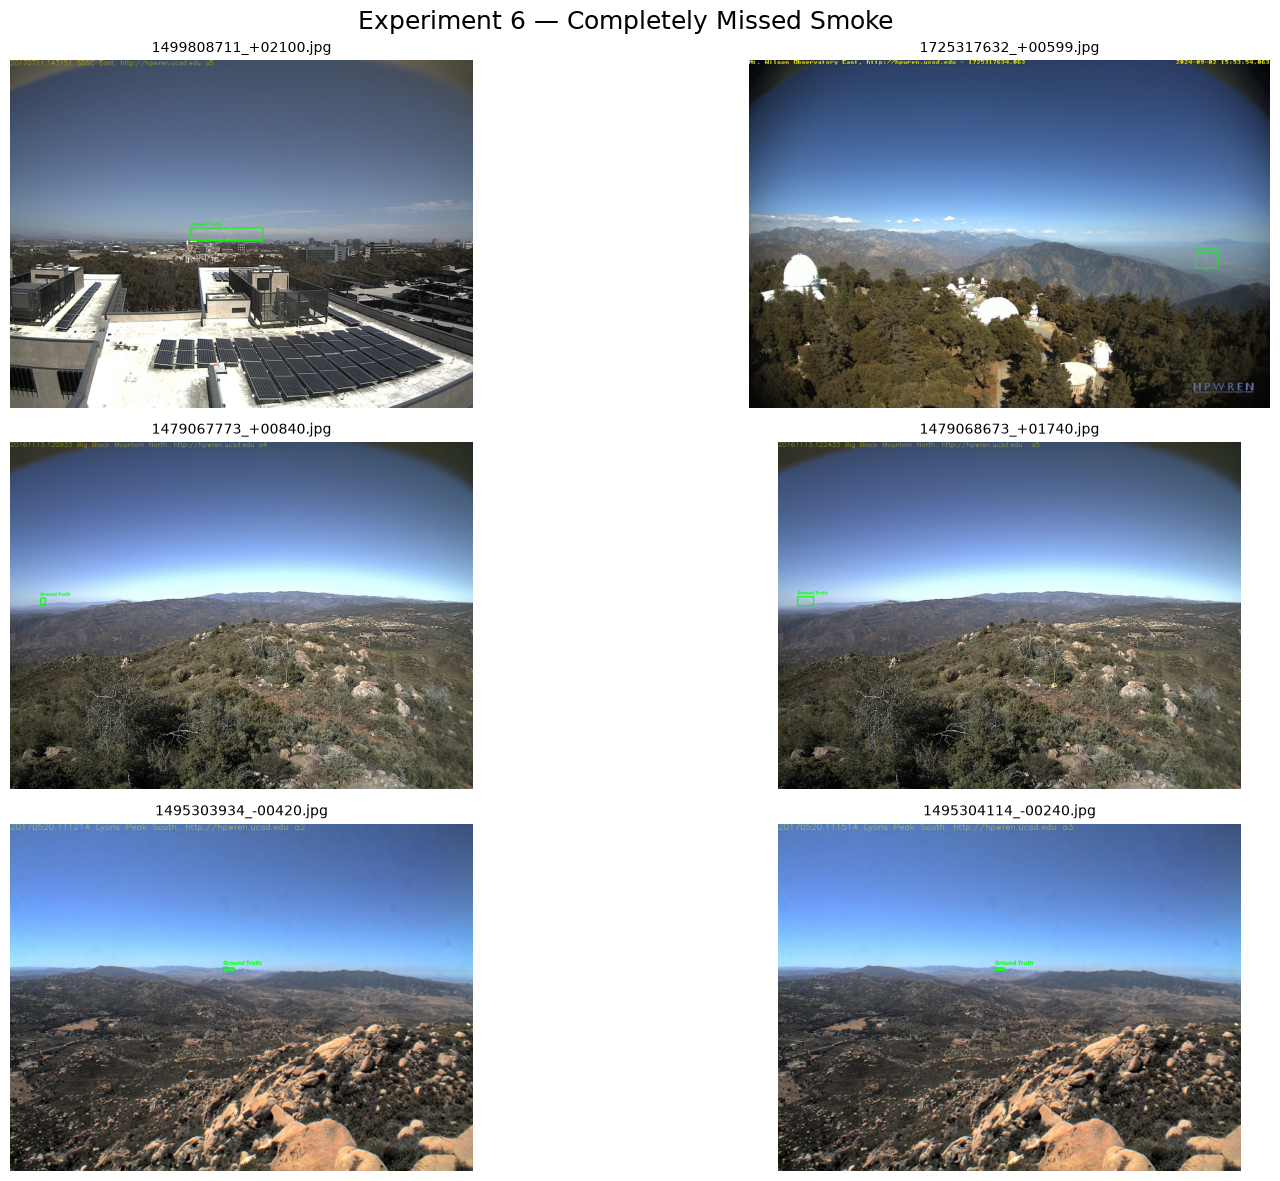

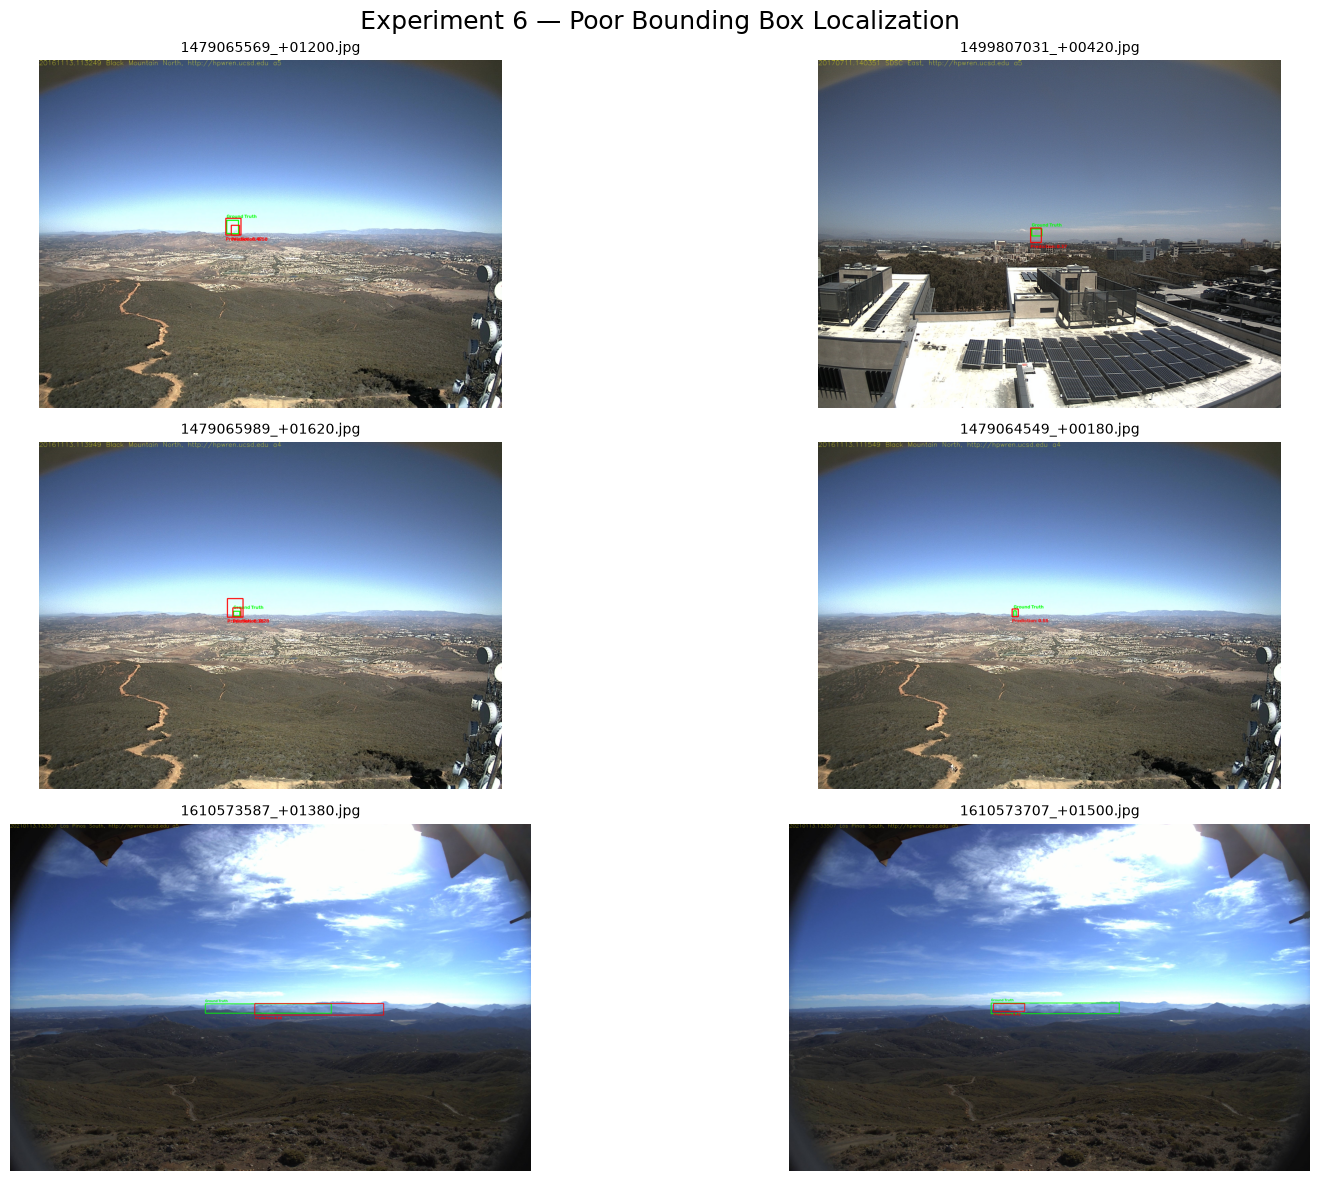

In [7]:
# ============================================================
# SECTION 12 — VISUAL ERROR ANALYSIS
# ============================================================

import cv2
import matplotlib.pyplot as plt

# Load the previous error analysis results
error_df = pd.read_csv(
    EVALUATION_DIR /
    "experiment_6_positive_errors" /
    "positive_error_analysis.csv"
)

# Select six completely missed smoke examples
missed_examples = error_df[
    error_df["Completely Missed"] > 0
].sample(n=6, random_state=42)

# Select six poor localization examples
localization_examples = error_df[
    error_df["Poor Localization"] > 0
].sample(n=6, random_state=42)


# Display images with ground truth and predicted boxes
def display_error_examples(examples, title):

    fig, axes = plt.subplots(3, 2, figsize=(18, 12))
    fig.suptitle(title, fontsize=18)

    for ax, (_, row) in zip(axes.flat, examples.iterrows()):

        filename = row["Image"]

        image_path = DATASET_DIR / "images" / "val" / filename
        label_path = (
            DATASET_DIR / "labels" / "val" /
            (Path(filename).stem + ".txt")
        )

        # Load image
        image = cv2.imread(str(image_path))
        height, width = image.shape[:2]

        # Run inference on one image
        result = model_exp6.predict(
            source=str(image_path),
            imgsz=960,
            conf=0.25,
            batch=1,
            device=0,
            verbose=False,
        )[0]

        # Draw ground-truth boxes in green
        for line in label_path.read_text().splitlines():

            if not line.strip():
                continue

            _, x, y, w, h = map(float, line.split())

            x1 = int((x - w / 2) * width)
            y1 = int((y - h / 2) * height)
            x2 = int((x + w / 2) * width)
            y2 = int((y + h / 2) * height)

            cv2.rectangle(
                image, (x1, y1), (x2, y2), (0, 255, 0), 3
            )

            cv2.putText(
                image, "Ground Truth",
                (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

        # Draw predicted boxes in red
        for box in result.boxes:

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].tolist()
            )

            confidence = float(box.conf.item())

            cv2.rectangle(
                image, (x1, y1), (x2, y2), (0, 0, 255), 3
            )

            cv2.putText(
                image, f"Prediction: {confidence:.2f}",
                (x1, min(y2 + 25, height - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 0, 255), 2
            )

        # Convert BGR to RGB for Matplotlib
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(filename, fontsize=10)
        ax.axis("off")

        del result, image

    plt.tight_layout()
    plt.show()
    plt.close(fig)


# Display both error categories
display_error_examples(
    missed_examples,
    "Experiment 6 — Completely Missed Smoke"
)

display_error_examples(
    localization_examples,
    "Experiment 6 — Poor Bounding Box Localization"
)

In [3]:
# ============================================================
# SECTION 13 — EXPERIMENT 5 HIGHER RESOLUTION EVALUATION
# ============================================================

# Load Experiment 5's trained YOLO11n checkpoint
checkpoint = (
    EXPERIMENTS_DIR /
    "experiment_5_full_dataset-2" /
    "weights" / "best.pt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

model_exp5 = YOLO(str(checkpoint))

# Evaluate at 1280 resolution without retraining
metrics_exp5_1280 = model_exp5.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=1280,
    batch=1,  # Reduce memory usage at higher resolution
    device=0,
    plots=True,
    project=str(EVALUATION_DIR),
    name="experiment_5_evaluation_1280",
    exist_ok=True,
)

# Extract evaluation metrics
p = metrics_exp5_1280.box.mp
r = metrics_exp5_1280.box.mr

results_exp5_1280 = pd.DataFrame([{
    "Model": "Experiment 5 — 1280 Inference",
    "Precision": p,
    "Recall": r,
    "F1": 2 * p * r / (p + r) if p + r else 0,
    "mAP50": metrics_exp5_1280.box.map50,
    "mAP50:95": metrics_exp5_1280.box.map,
}])

print("\nEXPERIMENT 5 — HIGHER RESOLUTION RESULTS")
display(results_exp5_1280.round(4))

Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1856.2±607.0 MB/s, size: 643.2 KB)
val: Scanning D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\labels\val.cache... 752 images, 313 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 752/752  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 752/752 15.7it/s 47.9s0.0ss
                   all        752        439      0.611      0.501       0.54       0.27
Speed: 3.4ms preprocess, 17.5ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to D:\Projects\Wildfire_Smoke_Project\evaluations\experiment_5_evaluation_1280

EXPERIMENT 5 — HIGHER RESOLUTION RESULTS


,Model,Precision,Recall,F1,mAP50,mAP50:95
0,Experiment 5 — 1280 Inference,0.6107,0.5011,0.5505,0.5397,0.2696


In [4]:
# ============================================================
# SECTION 14 — EXPERIMENT 7 HIGH-RESOLUTION FINE-TUNING
# ============================================================

# Load the best weights from Experiment 5
checkpoint = (
    EXPERIMENTS_DIR /
    "experiment_5_full_dataset-2" /
    "weights" / "best.pt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

# Initialize using previously trained weights
model_exp7 = YOLO(str(checkpoint))

# Fine-tune the existing model at a higher resolution
results_exp7 = model_exp7.train(
    data=str(DATA_YAML),
    epochs=20,
    imgsz=1280,
    batch=2,
    device=0,
    optimizer="AdamW",
    lr0=0.001,
    seed=42,
    deterministic=True,
    workers=0,
    cache=False,
    amp=False,
    project=str(EXPERIMENTS_DIR),
    name="experiment_7_high_resolution_finetune",
    exist_ok=False,
)

New https://pypi.org/project/ultralytics/8.4.218 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max

In [5]:
# ============================================================
# SECTION 15 — EXPERIMENT 7 EVALUATION
# ============================================================

# Load the best checkpoint saved during training
checkpoint = (
    EXPERIMENTS_DIR /
    "experiment_7_high_resolution_finetune" /
    "weights" / "best.pt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

model_exp7 = YOLO(str(checkpoint))

# Evaluate using the same validation dataset as Experiments 5 and 6
metrics_exp7 = model_exp7.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=1280,
    batch=1,
    device=0,
    plots=True,
    project=str(EVALUATION_DIR),
    name="experiment_7_evaluation",
    exist_ok=True,
)

# Extract evaluation metrics
p = metrics_exp7.box.mp
r = metrics_exp7.box.mr

results_exp7 = pd.DataFrame([{
    "Model": "Experiment 7 — High-Resolution Fine-Tuning",
    "Precision": p,
    "Recall": r,
    "F1": 2 * p * r / (p + r) if p + r else 0,
    "mAP50": metrics_exp7.box.map50,
    "mAP50:95": metrics_exp7.box.map,
}])

print("\nEXPERIMENT 7 — EVALUATION RESULTS")
display(results_exp7.round(4))

Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2026.6±307.1 MB/s, size: 707.5 KB)
val: Scanning D:\Projects\Wildfire_Smoke_Project\datasets\experiment_5\labels\val.cache... 752 images, 313 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 752/752  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 752/752 13.8it/s 54.6s0.0ss
                   all        752        439      0.621      0.526      0.539      0.282
Speed: 4.1ms preprocess, 24.1ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to D:\Projects\Wildfire_Smoke_Project\evaluations\experiment_7_evaluation

EXPERIMENT 7 — EVALUATION RESULTS


,Model,Precision,Recall,F1,mAP50,mAP50:95
0,Experiment 7 — High-Resolution Fine-Tuning,0.6209,0.526,0.5695,0.5391,0.2816
